## Module 3: Computational Drug Discovery Project 



## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 

Obesity is a chronic disease caused by complex interactions among biological, behavioral, environmental, and social factors. In 2024, approximately 16% of adults worldwide were living with obesity, and obesity increases the risk of conditions including type 2 diabetes, cardiovascular disease, liver and kidney disease, and some cancers (World Health Organization, 2026).

Treatment commonly begins with changes in diet, physical activity, and behavior. When these approaches are not sufficient, weight-management medications or bariatric surgery may also be used. GLP-1 receptor agonists such as semaglutide can reduce appetite and food intake and are used for long-term weight management. However, obesity often requires chronic treatment, some weight is commonly regained after stopping medication, and insurance coverage for weight-management medications varies (NIDDK, n.d.).

These limitations create a need for additional effective and accessible therapies. In this project, Cavalitide is evaluated as a potential GLP-1 receptor agonist that may compete with semaglutide.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Using data file: c:\Users\prith\Downloads\Classes at UVA\Computational BME\Module 3\Module_3___Saucerman_export\cavalitide_data.csv
Brute-force Kd = 0.0739 nM
Brute-force SSE = 0.00538
Curve-fit Kd = 0.0770 nM
Curve-fit SSE = 0.00515


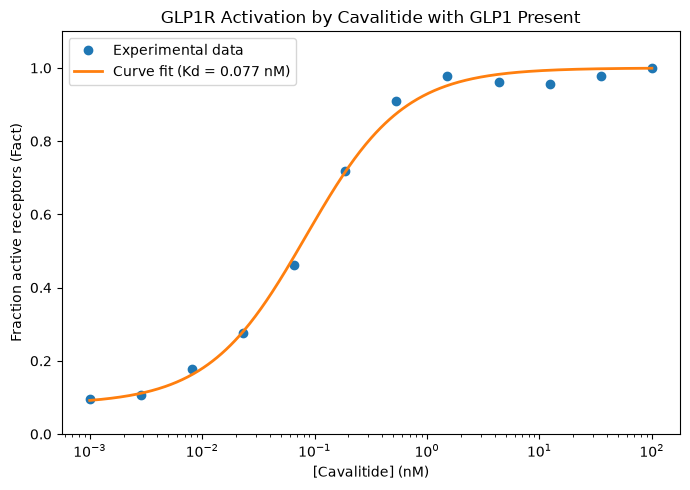

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path

# Fractional receptor activation with GLP1 and Cavalitide
def Fact(L1, L2, Kd1, Kd2):
    return (Kd2 * L1 + Kd1 * L2) / (
        Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2
    )

# Known GLP1 parameters
Kd1 = 0.17
L1 = 0.015

# Find cavalitide_data.csv
cwd = Path.cwd()

possible_files = [
    cwd / "cavalitide_data.csv",
    cwd.parent / "cavalitide_data.csv",
    cwd.parent.parent / "cavalitide_data.csv"
]

data_file = None

for file in possible_files:
    if file.exists():
        data_file = file
        break

# If it was not in one of the expected folders, search nearby
if data_file is None:
    search_results = list(cwd.parent.rglob("cavalitide_data.csv"))

    if len(search_results) > 0:
        data_file = search_results[0]
    else:
        raise FileNotFoundError(
            "Could not find cavalitide_data.csv"
        )

print("Using data file:", data_file)

# Load Cavalitide experimental data
data = np.loadtxt(
    data_file,
    delimiter=",",
    skiprows=1
)

L2_loaded = data[:, 0]
Fact_loaded = data[:, 1]

# Brute-force optimization
Kd2_candidates = np.logspace(-3, 2, 100)

SSE_brute = np.inf

for Kd2_try in Kd2_candidates:
    SSE = np.sum(
        (Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try)) ** 2
    )

    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try

# Nonlinear curve fitting
popt, pcov = curve_fit(
    lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
    L2_loaded,
    Fact_loaded,
    p0=[0.1],
    bounds=(0, np.inf)
)

Kd2_fit = popt[0]

SSE_fit = np.sum(
    (Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit)) ** 2
)

# Print results
print(f"Brute-force Kd = {Kd2_brute:.4f} nM")
print(f"Brute-force SSE = {SSE_brute:.5f}")

print(f"Curve-fit Kd = {Kd2_fit:.4f} nM")
print(f"Curve-fit SSE = {SSE_fit:.5f}")

# Smooth Cavalitide concentration range for fitted curve
L2 = np.logspace(-3, 2, 500)

# Plot
plt.figure(figsize=(7, 5))

plt.semilogx(
    L2_loaded,
    Fact_loaded,
    "o",
    label="Experimental data"
)

plt.semilogx(
    L2,
    Fact(L1, L2, Kd1, Kd2_fit),
    linewidth=2,
    label=f"Curve fit (Kd = {Kd2_fit:.3f} nM)"
)

plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("GLP1R Activation by Cavalitide with GLP1 Present")
plt.ylim(0, 1.1)
plt.legend()
plt.tight_layout()
plt.show()

### Task 1 Results

Both brute-force optimization and nonlinear curve fitting produced similar estimates of Cavalitide receptor affinity. Brute force gave a \(K_d\) of approximately **0.0739 nM** with an SSE of **0.00538**, while nonlinear curve fitting gave a \(K_d\) of approximately **0.0770 nM** with a slightly lower SSE of **0.00515**. Therefore, the nonlinear curve-fit value of **0.077 nM** was used as the best estimate because it provided the smaller fitting error.

For comparison, the fitted \(K_d\) of semaglutide was approximately **0.350 nM**. Since a lower \(K_d\) indicates stronger receptor affinity, Cavalitide is predicted to bind GLP1R more strongly than semaglutide and may require a lower concentration to produce similar receptor activation. However, stronger receptor binding alone does not mean Cavalitide will be a better drug because factors such as absorption, elimination, dosing frequency, bioavailability, and safety must also be considered.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

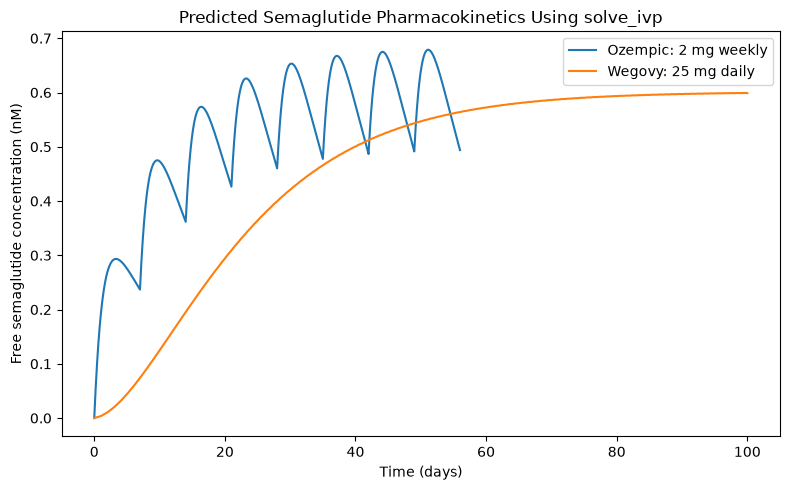

Ozempic final free blood concentration: 0.49393024886870096 nM
Wegovy final free blood concentration: 0.5988672781387003 nM


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Shared PK parameters
ke = 0.0039      # elimination rate [1/h]
V = 10.8         # volume [L]
MW = 4113.6      # molecular weight [g/mol]
Ffree = 0.01     # fraction free in blood

# Semaglutide products
products = {
    "Ozempic": {
        "Favailable": 0.89,
        "ka": 0.029,
        "D": 2.0,
        "interval": 168,
        "n_doses": 8,
        "depot": "subcutaneous"
    },

    "Wegovy": {
        "Favailable": 0.01,
        "ka": 0.0029,
        "D": 25,
        "interval": 24,
        "n_doses": 100,
        "depot": "oral"
    }
}


def simulate_pk(Favailable, ka, D, interval, n_doses):

    # Initial depot amount and blood concentration
    y = np.array([0.0, 0.0])

    t_all = []
    depot_all = []
    blood_all = []

    def ODEfunc(t, y):
        A_depot, C_blood = y

        dA_depot = -ka * A_depot
        dC_blood = ka * A_depot / V - ke * C_blood

        return [dA_depot, dC_blood]

    for i in range(n_doses):

        # Add a new dose to the depot
        y[0] += Favailable * D

        t_start = i * interval
        t_end = (i + 1) * interval

        t_eval = np.linspace(
            t_start,
            t_end,
            200
        )

        solution = solve_ivp(
            ODEfunc,
            [t_start, t_end],
            y,
            t_eval=t_eval
        )

        t_all.append(solution.t)
        depot_all.append(solution.y[0])
        blood_all.append(solution.y[1])

        # Carry the final state into the next dose
        y = solution.y[:, -1]

    t = np.concatenate(t_all)
    depot = np.concatenate(depot_all)
    blood = np.concatenate(blood_all)

    # Convert blood concentration from mg/L to nM
    blood_nM = blood * 1e-3 / MW * 1e9

    # Calculate free drug concentration
    free_blood_nM = Ffree * blood_nM

    return t, depot, free_blood_nM


# Run Ozempic simulation
oz = products["Ozempic"]

t_oz, depot_oz, blood_oz = simulate_pk(
    oz["Favailable"],
    oz["ka"],
    oz["D"],
    oz["interval"],
    oz["n_doses"]
)


# Run Wegovy simulation
weg = products["Wegovy"]

t_weg, depot_weg, blood_weg = simulate_pk(
    weg["Favailable"],
    weg["ka"],
    weg["D"],
    weg["interval"],
    weg["n_doses"]
)


# Plot free blood concentrations
plt.figure(figsize=(8, 5))

plt.plot(
    t_oz / 24,
    blood_oz,
    label="Ozempic: 2 mg weekly"
)

plt.plot(
    t_weg / 24,
    blood_weg,
    label="Wegovy: 25 mg daily"
)

plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide concentration (nM)")
plt.title("Predicted Semaglutide Pharmacokinetics Using solve_ivp")

plt.legend()
plt.tight_layout()
plt.show()


print(
    "Ozempic final free blood concentration:",
    blood_oz[-1],
    "nM"
)

print(
    "Wegovy final free blood concentration:",
    blood_weg[-1],
    "nM"
)

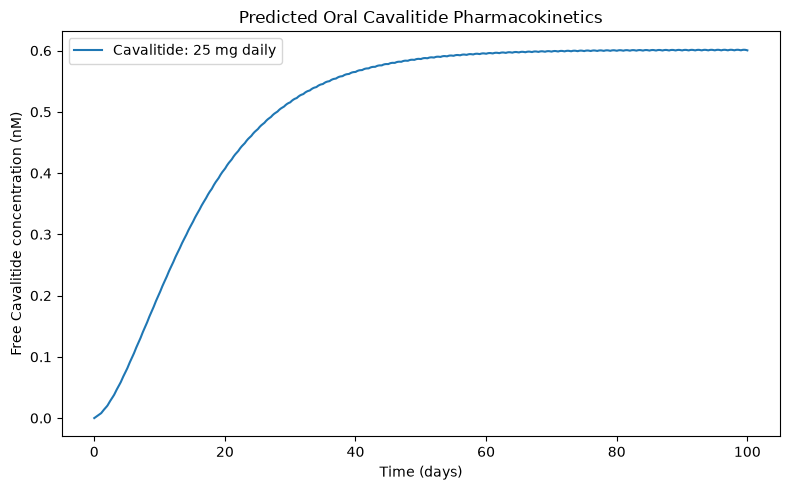

Cavalitide final free blood concentration: 0.6003838376929711 nM


In [22]:
# Task 2b: Simulate oral Cavalitide pharmacokinetics

# Cavalitide parameters
Favailable_cav = 0.01
ka_cav = 0.006          # increased absorption rate [1/h]
D_cav = 25              # starting oral dose [mg]
interval_cav = 24       # daily dosing [h]
n_doses_cav = 100       # simulate 100 days

# Run Cavalitide simulation
t_cav, depot_cav, blood_cav = simulate_pk(
    Favailable_cav,
    ka_cav,
    D_cav,
    interval_cav,
    n_doses_cav
)

# Plot Cavalitide free blood concentration
plt.figure(figsize=(8, 5))

plt.plot(
    t_cav / 24,
    blood_cav,
    label="Cavalitide: 25 mg daily"
)

plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide concentration (nM)")
plt.title("Predicted Oral Cavalitide Pharmacokinetics")

plt.legend()
plt.tight_layout()
plt.show()

print(
    "Cavalitide final free blood concentration:",
    blood_cav[-1],
    "nM"
)

Optimized daily dose: 20.820014156331013 mg


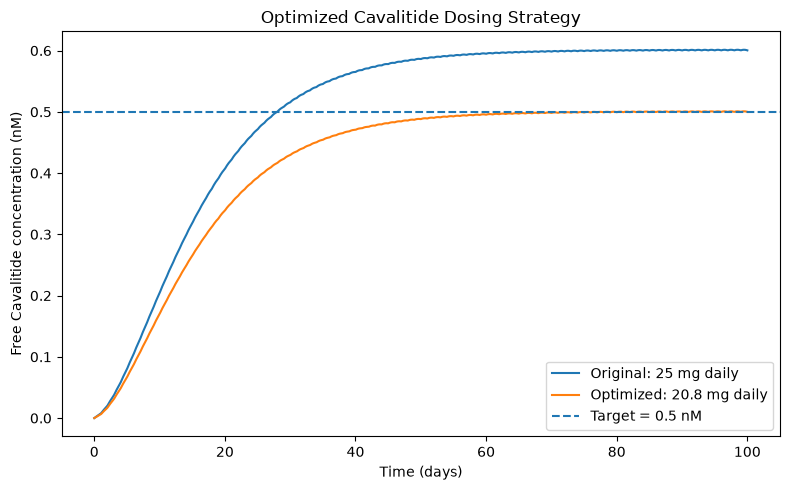

Final optimized free blood concentration: 0.5000000000001461 nM


In [23]:
# Task 2c: Optimize Cavalitide dosing to reach about 0.5 nM

target_concentration = 0.5  # nM

# Starting dose from Task 2b
starting_dose = 25.0  # mg

# Scale the dose based on the concentration from Task 2b
optimized_dose = starting_dose * (
    target_concentration / blood_cav[-1]
)

print(
    "Optimized daily dose:",
    optimized_dose,
    "mg"
)

# Run optimized Cavalitide simulation
t_cav_opt, depot_cav_opt, blood_cav_opt = simulate_pk(
    Favailable_cav,
    ka_cav,
    optimized_dose,
    interval_cav,
    n_doses_cav
)

# Plot original and optimized dosing
plt.figure(figsize=(8, 5))

plt.plot(
    t_cav / 24,
    blood_cav,
    label="Original: 25 mg daily"
)

plt.plot(
    t_cav_opt / 24,
    blood_cav_opt,
    label=f"Optimized: {optimized_dose:.1f} mg daily"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Target = 0.5 nM"
)

plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide concentration (nM)")
plt.title("Optimized Cavalitide Dosing Strategy")

plt.legend()
plt.tight_layout()
plt.show()

print(
    "Final optimized free blood concentration:",
    blood_cav_opt[-1],
    "nM"
)

### Task 2 Results

Using `solve_ivp`, the pharmacokinetic model predicted different concentration profiles for weekly injected Ozempic and daily oral Wegovy. Ozempic showed repeated peaks and troughs because of weekly dosing, while Wegovy increased more gradually toward steady state because it was administered daily.

For Cavalitide, a starting oral dose of 25 mg daily with an absorption rate of \(k_a = 0.006\ \text{h}^{-1}\) produced a steady-state free blood concentration of approximately **0.60 nM**, which was above the desired 0.5 nM target. The daily dose was therefore reduced to approximately **20.8 mg**, producing a steady-state concentration close to **0.5 nM**.

Reducing the dose while maintaining daily administration allows the model to reach the desired blood concentration while using less drug, which could potentially reduce unnecessary exposure and adverse effects.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


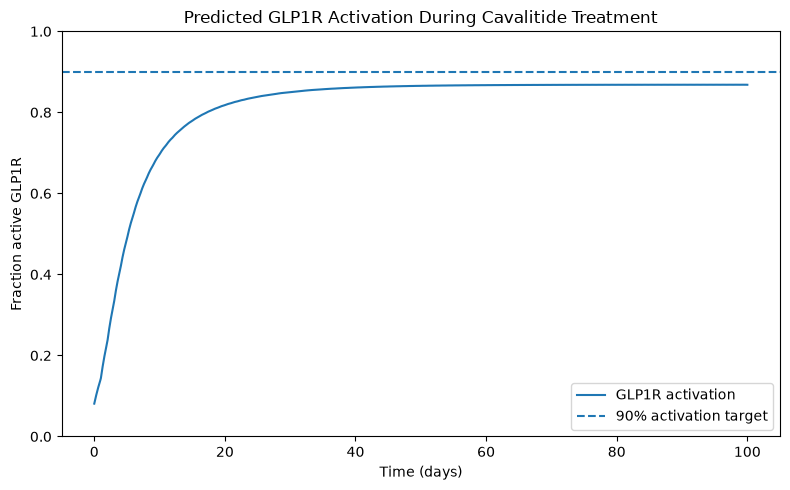

GLP1R activation at day 100: 0.8681041866089303
Percent GLP1R activation at day 100: 86.81041866089303 %


In [24]:
# Task 3a: Combine Cavalitide PK and PD models

# Receptor-binding parameters
Kd_GLP1 = 0.17        # GLP1 Kd [nM]
GLP1 = 0.015          # fasting GLP1 concentration [nM]
Kd_Cavalitide = 0.077 # fitted Cavalitide Kd from Task 1 [nM]

# Fractional receptor activation model
def receptor_activation(GLP1, Cavalitide, Kd_GLP1, Kd_Cavalitide):
    return (
        Kd_Cavalitide * GLP1
        + Kd_GLP1 * Cavalitide
    ) / (
        Kd_GLP1 * Kd_Cavalitide
        + Kd_Cavalitide * GLP1
        + Kd_GLP1 * Cavalitide
    )

# Use optimized Cavalitide blood concentrations from Task 2
activation = receptor_activation(
    GLP1,
    blood_cav_opt,
    Kd_GLP1,
    Kd_Cavalitide
)

# Plot receptor activation over time
plt.figure(figsize=(8, 5))

plt.plot(
    t_cav_opt / 24,
    activation,
    label="GLP1R activation"
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90% activation target"
)

plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R")
plt.title("Predicted GLP1R Activation During Cavalitide Treatment")

plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "GLP1R activation at day 100:",
    activation[-1]
)

print(
    "Percent GLP1R activation at day 100:",
    activation[-1] * 100,
    "%"
)

Cavalitide concentration needed for 90% activation: 0.6862058823529413 nM
Optimized Phase 2 daily dose: 28.573632369483356 mg


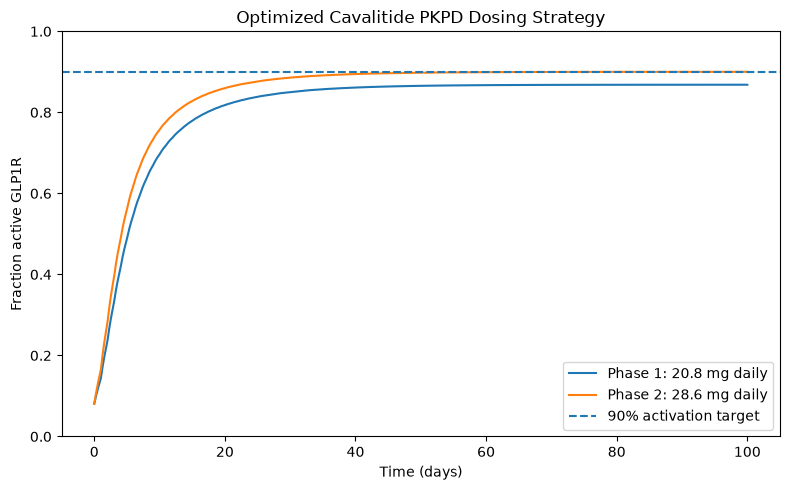

Final Phase 2 free blood concentration: 0.6862058823526158 nM
Final Phase 2 GLP1R activation: 0.8999999999999577
Final Phase 2 GLP1R activation: 89.99999999999577 %


In [25]:
# Task 3b: Optimize Cavalitide dose for about 90% GLP1R activation

target_activation = 0.90

# Calculate the Cavalitide concentration needed for 90% activation
target_cavalitide_concentration = (
    (
        target_activation
        * Kd_GLP1
        * Kd_Cavalitide
        / (1 - target_activation)
    )
    - (Kd_Cavalitide * GLP1)
) / Kd_GLP1

print(
    "Cavalitide concentration needed for 90% activation:",
    target_cavalitide_concentration,
    "nM"
)

# Scale the Phase 1 dose based on the required concentration
phase1_dose = optimized_dose

phase2_dose = phase1_dose * (
    target_cavalitide_concentration
    / blood_cav_opt[-1]
)

print(
    "Optimized Phase 2 daily dose:",
    phase2_dose,
    "mg"
)

# Run PK model using the new Phase 2 dose
t_phase2, depot_phase2, blood_phase2 = simulate_pk(
    Favailable_cav,
    ka_cav,
    phase2_dose,
    interval_cav,
    n_doses_cav
)

# Calculate receptor activation over time
activation_phase2 = receptor_activation(
    GLP1,
    blood_phase2,
    Kd_GLP1,
    Kd_Cavalitide
)

# Plot Phase 1 and Phase 2 receptor activation
plt.figure(figsize=(8, 5))

plt.plot(
    t_cav_opt / 24,
    activation,
    label=f"Phase 1: {phase1_dose:.1f} mg daily"
)

plt.plot(
    t_phase2 / 24,
    activation_phase2,
    label=f"Phase 2: {phase2_dose:.1f} mg daily"
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90% activation target"
)

plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R")
plt.title("Optimized Cavalitide PKPD Dosing Strategy")

plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Final Phase 2 free blood concentration:",
    blood_phase2[-1],
    "nM"
)

print(
    "Final Phase 2 GLP1R activation:",
    activation_phase2[-1]
)

print(
    "Final Phase 2 GLP1R activation:",
    activation_phase2[-1] * 100,
    "%"
)

### Task 3 Results

The combined PKPD model predicted that the Phase 1 dosing strategy of approximately **20.8 mg Cavalitide daily** would produce about **86.8% GLP1R activation** at steady state. This was below the Phase 2 target of approximately 90% receptor activation.

To reach the 90% target, the required steady-state free Cavalitide concentration was calculated to be approximately **0.686 nM**. The daily dose was therefore increased from approximately **20.8 mg to 28.6 mg**. This optimized Phase 2 dosing strategy produced approximately **90.0% GLP1R activation** at day 100.

Increasing the daily dose increased receptor activation while keeping the dosing schedule unchanged. Clinically, this adjustment could potentially improve drug efficacy by producing greater GLP1R activation, although the higher dose could also increase drug exposure and the risk of adverse effects. Therefore, the benefits of increased receptor activation would need to be balanced against safety and tolerability.

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*